(235795, 55)
URL Only models fitted.
URL + HTML models fitted.
TF-IDF models fitted.


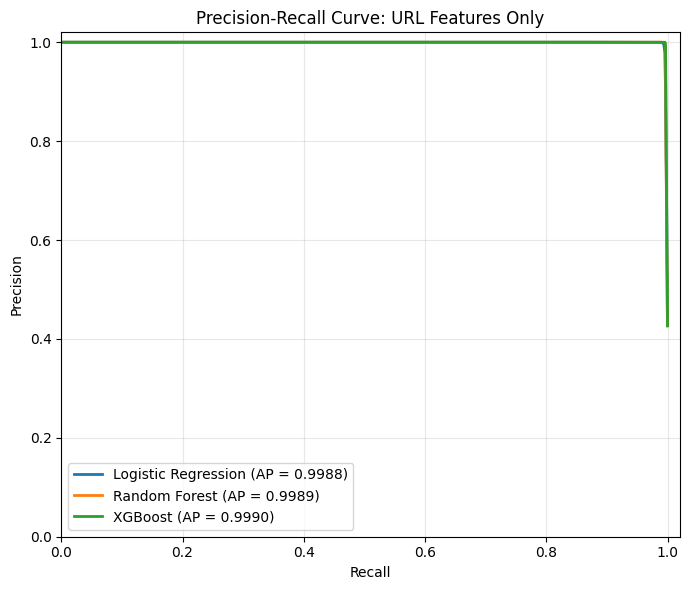

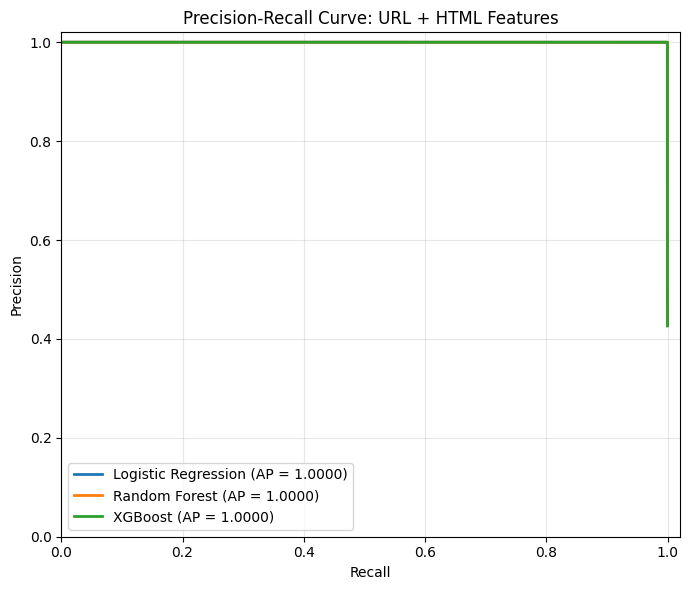

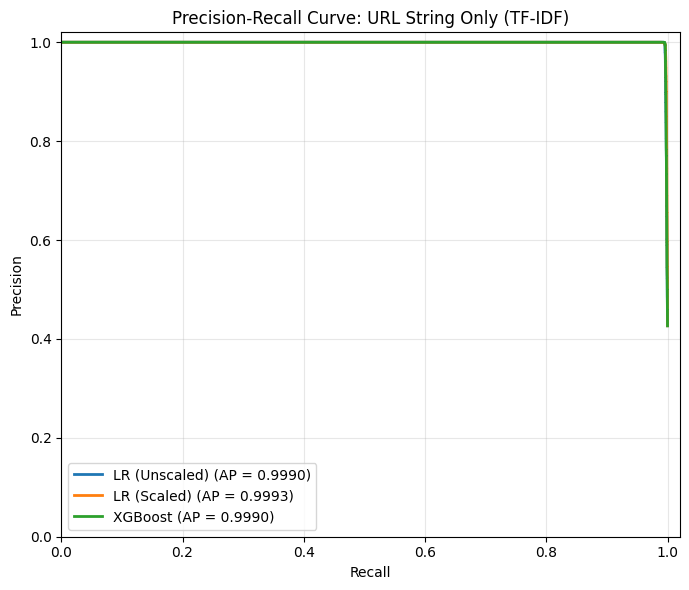

In [ ]:
!pip install ucimlrepo xgboost -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import precision_recall_curve, average_precision_score
from xgboost import XGBClassifier

# load PhiUSIIL and invert labels
phiusiil = fetch_ucirepo(id=967)
X = phiusiil.data.features
y = phiusiil.data.targets
data = pd.concat([X, y], axis=1)
data['label'] = data['label'].map({0: 1, 1: 0})
print(data.shape)

# feature configuration drop lists

# scores calculated after downloading webpage HTML
webpage_features_to_drop = [
    'LineOfCode', 'LargestLineLength', 'HasTitle',
    'HasFavicon', 'Robots', 'IsResponsive',
    'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup',
    'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
    'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
    'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
    'NoOfEmptyRef', 'NoOfExternalRef'
]

# derived features from URL
derived_features_to_drop = [
    'CharContinuationRate',
    'URLSimilarityIndex',
    'URLTitleMatchScore',
    'URLCharProb',
    'TLDLegitimateProb',
    'DomainTitleMatchScore'
]

# URL features only: drop non-numeric + webpage + derived
columns_to_drop_num = ['label', 'URL', 'Domain', 'TLD', 'Title']
columns_to_drop_num.extend(webpage_features_to_drop)
columns_to_drop_num.extend(derived_features_to_drop)

# URL + HTML: drop non-numeric + derived only
columns_to_drop_web = ['label', 'URL', 'Domain', 'TLD', 'Title']
columns_to_drop_web.extend(derived_features_to_drop)

# PR-curve plotting helper

def plot_pr_curves(models, X_test, y_test, title, save_path):
    """models: dict of {display_label: fitted_pipeline_with_predict_proba}"""
    plt.figure(figsize=(7, 6))
    for label, pipe in models.items():
        y_proba = pipe.predict_proba(X_test)[:, 1]
        precision, recall, _ = precision_recall_curve(y_test, y_proba)
        ap = average_precision_score(y_test, y_proba)
        plt.plot(recall, precision, label=f"{label} (AP = {ap:.4f})", linewidth=2)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(title)
    plt.legend(loc="lower left")
    plt.grid(alpha=0.3)
    plt.xlim([0.0, 1.02])
    plt.ylim([0.0, 1.02])
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()

# URL features only

y_num = data['label']
X_num = data.drop(columns=columns_to_drop_num)

X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(
    X_num, y_num, test_size=0.2, random_state=35)

lr_pipe = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=2000))])
lr_pipe.fit(X_train_num, y_train_num)

rf_pipe = Pipeline([('rf', RandomForestClassifier(n_estimators=100))])
rf_pipe.fit(X_train_num, y_train_num)

xgb_pipe = Pipeline([('xgb', XGBClassifier(n_estimators=100, max_depth=6))])
xgb_pipe.fit(X_train_num, y_train_num)

print("URL Only models fitted.")

# URL + HTML features

y_web = data['label']
X_web = data.drop(columns=columns_to_drop_web)

X_train_web, X_test_web, y_train_web, y_test_web = train_test_split(
    X_web, y_web, test_size=0.2, random_state=35)

lr_web_pipe = Pipeline([('scaler', StandardScaler()), ('lr', LogisticRegression(max_iter=2000))])
lr_web_pipe.fit(X_train_web, y_train_web)

rf_web_pipe = Pipeline([('rf', RandomForestClassifier(n_estimators=100))])
rf_web_pipe.fit(X_train_web, y_train_web)

xgb_web_pipe = Pipeline([('xgb', XGBClassifier(n_estimators=100, max_depth=6))])
xgb_web_pipe.fit(X_train_web, y_train_web)

print("URL + HTML models fitted.")

# URL string only

y_url = data['label']
X_url = data['URL']

X_train_url, X_test_url, y_train_url, y_test_url = train_test_split(
    X_url, y_url, test_size=0.2, random_state=35)

pipe_char_no_scale = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)),
    ('clf', LogisticRegression(max_iter=2000))
])
pipe_char_no_scale.fit(X_train_url, y_train_url)

pipe_char = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)),
    ('scaler', StandardScaler(with_mean=False)),
    ('clf', LogisticRegression(max_iter=2000))
])
pipe_char.fit(X_train_url, y_train_url)

pipe_xgb_char = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)),
    ('xgb', XGBClassifier(n_estimators=100, max_depth=6))
])
pipe_xgb_char.fit(X_train_url, y_train_url)

print("TF-IDF models fitted.")

# generate PR curves

plot_pr_curves(
    {'Logistic Regression': lr_pipe, 'Random Forest': rf_pipe, 'XGBoost': xgb_pipe},
    X_test_num, y_test_num,
    title="Precision-Recall Curve: URL Features Only",
    save_path="pr_curve_url_only.png"
)

plot_pr_curves(
    {'Logistic Regression': lr_web_pipe, 'Random Forest': rf_web_pipe, 'XGBoost': xgb_web_pipe},
    X_test_web, y_test_web,
    title="Precision-Recall Curve: URL + HTML Features",
    save_path="pr_curve_url_html.png"
)

plot_pr_curves(
    {'LR (Unscaled)': pipe_char_no_scale, 'LR (Scaled)': pipe_char, 'XGBoost': pipe_xgb_char},
    X_test_url, y_test_url,
    title="Precision-Recall Curve: URL String Only (TF-IDF)",
    save_path="pr_curve_tfidf.png"
)

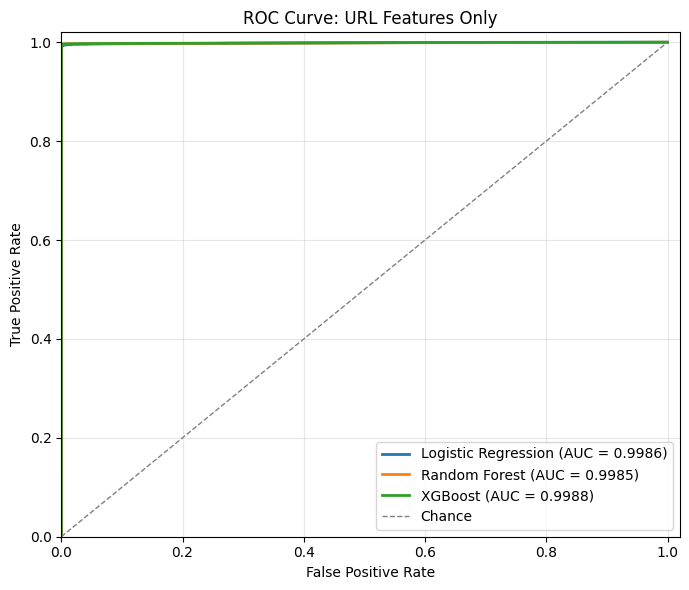

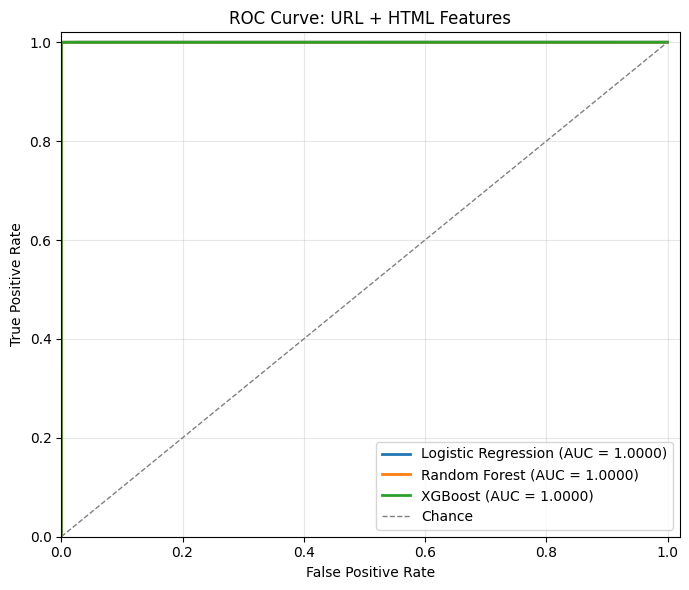

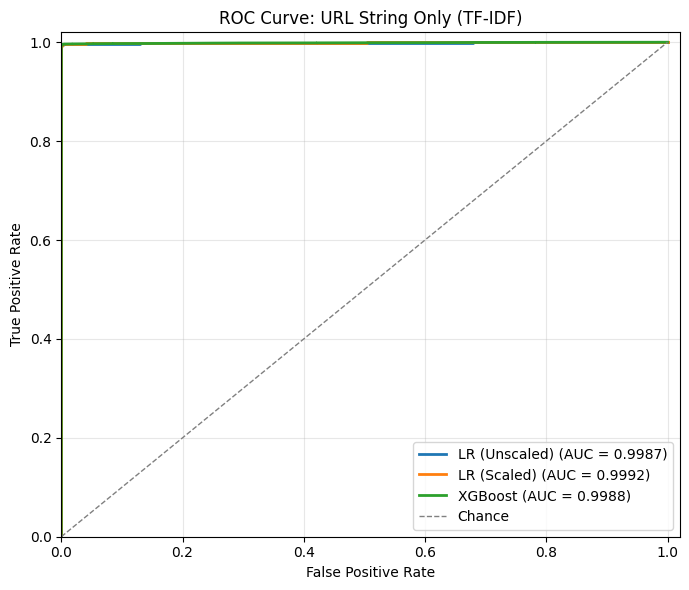

In [ ]:
# plot ROC-AUC curves

from sklearn.metrics import roc_curve, roc_auc_score

def plot_roc_curves(models, X_test, y_test, title, save_path):
    """models: dict of {display_label: fitted_pipeline_with_predict_proba}"""
    plt.figure(figsize=(7, 6))
    for label, pipe in models.items():
        y_proba = pipe.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_proba)
        auc = roc_auc_score(y_test, y_proba)
        plt.plot(fpr, tpr, label=f"{label} (AUC = {auc:.4f})", linewidth=2)
    plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Chance")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(title)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.xlim([0.0, 1.02])
    plt.ylim([0.0, 1.02])
    plt.tight_layout()
    plt.savefig(save_path, dpi=200)
    plt.show()

plot_roc_curves(
    {'Logistic Regression': lr_pipe, 'Random Forest': rf_pipe, 'XGBoost': xgb_pipe},
    X_test_num, y_test_num,
    title="ROC Curve: URL Features Only",
    save_path="roc_curve_url_only.png"
)

plot_roc_curves(
    {'Logistic Regression': lr_web_pipe, 'Random Forest': rf_web_pipe, 'XGBoost': xgb_web_pipe},
    X_test_web, y_test_web,
    title="ROC Curve: URL + HTML Features",
    save_path="roc_curve_url_html.png"
)

plot_roc_curves(
    {'LR (Unscaled)': pipe_char_no_scale, 'LR (Scaled)': pipe_char, 'XGBoost': pipe_xgb_char},
    X_test_url, y_test_url,
    title="ROC Curve: URL String Only (TF-IDF)",
    save_path="roc_curve_tfidf.png"
)

In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score

configs = {
    'URL Features Only': (X_test_num, y_test_num, {
        'Logistic Regression': lr_pipe, 'Random Forest': rf_pipe, 'XGBoost': xgb_pipe
    }),
    'URL + HTML Features': (X_test_web, y_test_web, {
        'Logistic Regression': lr_web_pipe, 'Random Forest': rf_web_pipe, 'XGBoost': xgb_web_pipe
    }),
    'URL String Only (TF-IDF)': (X_test_url, y_test_url, {
        'LR (Unscaled)': pipe_char_no_scale, 'LR (Scaled)': pipe_char, 'XGBoost': pipe_xgb_char
    }),
}

results = []
for config_name, (X_test, y_test, models) in configs.items():
    for model_name, pipe in models.items():
        y_proba = pipe.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_proba)
        ap = average_precision_score(y_test, y_proba)
        results.append({'Configuration': config_name, 'Model': model_name, 'AUC': auc, 'AP': ap})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

print(f"\nAUC range: [{results_df['AUC'].min():.4f}, {results_df['AUC'].max():.4f}]")
print(f"AP range:  [{results_df['AP'].min():.4f}, {results_df['AP'].max():.4f}]")

           Configuration               Model      AUC       AP
       URL Features Only Logistic Regression 0.998594 0.998814
       URL Features Only       Random Forest 0.998523 0.998871
       URL Features Only             XGBoost 0.998831 0.999045
     URL + HTML Features Logistic Regression 0.999994 0.999992
     URL + HTML Features       Random Forest 0.999999 0.999999
     URL + HTML Features             XGBoost 1.000000 1.000000
URL String Only (TF-IDF)       LR (Unscaled) 0.998728 0.998970
URL String Only (TF-IDF)         LR (Scaled) 0.999210 0.999314
URL String Only (TF-IDF)             XGBoost 0.998772 0.999007

AUC range: [0.9985, 1.0000]
AP range:  [0.9988, 1.0000]
